<a href="https://colab.research.google.com/github/MideCS/Naijattention/blob/main/notebooks/naijattention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluating Contrastive Learning for English → Nigerian Pidgin Translation

**Research question.** With training data, architecture, budget and decoding held fixed, does adding a
cross-lingual sentence-level contrastive objective to translation cross-entropy improve (a) English→Pidgin
translation quality (chrF++) and/or (b) English–Pidgin encoder embedding alignment (top-1 retrieval)?

| Experiment | Initialisation | Objective | Inference |
|---|---|---|---|
| Baseline | `google/mt5-small` | translation CE | encoder–decoder EN→PCM |
| Contrastive | fresh `google/mt5-small`, same seed | CE + λ · symmetric InfoNCE | identical |

```
English (+ task prefix) ──► mT5 encoder ──► decoder ──► Pidgin      (L_MT, both models)
        │                        │
        └── mean-pool (sentence tokens) ──┐
Pidgin reference ──► same encoder ──► mean-pool ──► InfoNCE over the batch (L_CL, contrastive model only)
```

Data: MAFAND-MT en-pcm (news), UD Naija-NSC (spoken), MTurk Pidgin CSV (training only), pinned to exact
upstream commits. Validation/test are the **published** MAFAND and Naija dev/test splits, reported per source.

**How to run on Colab (A100):** Runtime → Run all with `RUN_MODE = "pilot"` (the default), check the
training-health table, then set `RUN_MODE = "full"` and Run all again. Outputs are saved to
`MyDrive/naijattention/outputs/`. If Colab disconnects, Run all again: finished training runs are reused.

## 1. Environment

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    os.chdir("/content")
    if Path("Naijattention").exists():
        subprocess.run(["git", "-C", "Naijattention", "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "https://github.com/MideCS/Naijattention.git"], check=True)
    os.chdir("Naijattention")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    # Outputs (checkpoints, results) go to Google Drive so they survive a disconnect. Re-running
    # the notebook after a disconnect reuses every finished training run and redoes only the rest.
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/naijattention/outputs")
else:  # local: run from the repo root regardless of where Jupyter was started
    root = Path.cwd()
    while not (root / "pyproject.toml").exists() and root != root.parent:
        root = root.parent
    os.chdir(root)
    OUTPUT_ROOT = Path("outputs")
sys.path.insert(0, str(Path.cwd() / "src"))
print("working directory:", Path.cwd(), "| outputs under:", OUTPUT_ROOT)

Mounted at /content/drive
working directory: /content/Naijattention | outputs under: /content/drive/MyDrive/naijattention/outputs


In [2]:
import json
from dataclasses import replace
import numpy as np, pandas as pd, torch
import matplotlib
from IPython.display import display, Image
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

from naijattention import Config
from naijattention import checks
from naijattention.data import SOURCES
from naijattention.modeling import PairCollator, truncation_report
from naijattention.train import make_loader, to_device, load_best
from naijattention.evaluate import translate_to_pidgin
from naijattention.pipeline import (prepare_data, planned_runs, train_all, pick_contrastive, evaluate_test,
                                    results_table, delta_table, plot_learning_curves, plot_alignment, integrity_checks)
from naijattention.utils import environment_report, free_memory, get_device, resolve_precision, save_json, seed_all

pd.set_option("display.max_colwidth", 120)
env = environment_report()
env

{'python': '3.13.16',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'torch': '2.14.1+cu130',
 'transformers': '4.57.6',
 'sacrebleu': '2.6.0',
 'numpy': '2.4.6',
 'cuda_available': True,
 'gpu': 'NVIDIA A100-SXM4-40GB',
 'gpu_memory_gb': 39.49,
 'bf16_supported': True,
 'cuda': '13.0'}

## 2. Configuration

Defaults follow the implementation plan with these deliberate changes: Adafactor at lr 1e-3 (the standard
mT5 recipe; 3e-5 AdamW barely moves mT5), batch 32 per step (more in-batch negatives), 10 epochs, BF16 or FP32
only (mT5 overflows in FP16), English pooled over sentence tokens only, and same-text rows in a batch
masked out as negatives. Change anything here; the full config is saved with the outputs.

In [3]:
#   "smoke": 64 training rows, a few minutes on any GPU/CPU - checks the code runs
#   "pilot": full data, 300 updates per model (~10-15 min on an A100) - checks LR, timing, full-size eval
#   "full" : the real experiment
RUN_MODE = os.environ.get("NAIJA_MODE", "pilot")   # <- set to "full" once the pilot looks healthy

overrides = dict(
    # train_subset_size=25000,      # None = all ~35k cleaned rows
    # lambda_sweep=[0.05, 0.5],     # extra contrastive runs; lambda chosen on validation chrF++ only
    # batch_size=16, gradient_accumulation_steps=2,   # if memory is tight (fewer negatives!)
)
preset = {"smoke": Config.smoke, "pilot": Config.pilot, "full": Config}[RUN_MODE]
cfg = preset()
cfg = replace(cfg, output_dir=str(OUTPUT_ROOT / Path(cfg.output_dir).name), **overrides)
device = get_device()
precision = resolve_precision(cfg.precision, device)
out = Path(cfg.output_dir); out.mkdir(parents=True, exist_ok=True)
cfg.save(out / "config.json"); save_json(env, out / "environment.json")
seed_all(cfg.seed)
print(f"RUN MODE: {cfg.run_label} | outputs: {out} | device: {device} | precision: {precision}")
if not cfg.is_research_run:
    print("NOTE: this is a", cfg.run_label, "run - its numbers are not research results.")
cfg

RUN MODE: pilot | outputs: /content/drive/MyDrive/naijattention/outputs/pilot | device: cuda | precision: bf16
NOTE: this is a pilot run - its numbers are not research results.


Config(seed=42, checkpoint='google/mt5-small', output_dir='/content/drive/MyDrive/naijattention/outputs/pilot', data_dir='data', overwrite=False, train_subset_size=None, source_prefix='translate English to Nigerian Pidgin: ', max_source_length=128, max_target_length=128, optimizer='adafactor', learning_rate=0.001, weight_decay=0.0, batch_size=32, gradient_accumulation_steps=1, eval_batch_size=64, epochs=1, max_train_steps=300, warmup_ratio=0.05, max_grad_norm=1.0, precision='auto', gradient_checkpointing=False, log_every=50, lambda_cl=0.1, lambda_sweep=[], temperature=0.07, pool_exclude_prefix=True, mask_duplicate_negatives=True, num_beams=4, max_new_tokens=128, bootstrap_samples=1000, human_eval_per_bucket=20, smoke_test=False, smoke_train_rows=64, smoke_eval_rows_per_source=16)

## 3. Data: load, audit, clean, leakage-filter, split

In [4]:
pd.DataFrame(SOURCES).T[["repo", "sha", "license", "domain"]]

,repo,sha,license,domain
mafand,masakhane-io/lafand-mt,c1a423500753a28b2fae8f5d5e1634de768cd89b,CC BY-NC 4.0,news
naija,UniversalDependencies/UD_Naija-NSC,8877d801f1ad9e5e7eb52f509d83f25d6695c2e1,CC BY-SA 4.0,spoken
mturk,Tommy0201/LowResource-Paper-Dataset,bf88f5e020232a2116059dddd486deb0edbd4124,unconfirmed - check before redistributing,unknown


In [5]:
splits, audit = prepare_data(cfg)
print(json.dumps({k: audit[k] for k in ["raw_counts", "leakage_removed", "duplicate_pairs_removed", "train_english_with_multiple_targets",
                                         "published_dev_test_overlap", "naija_cross_split_overlap",
                                         "eval_repeated_pidgin_rows", "split_counts"]}, indent=1))
print("provenance dropped rows:", audit["provenance"]["dropped_missing_fields"])
print("invariants:", audit["invariants"])

final split sizes: train=35058, validation=2474, test=2536
{
 "raw_counts": {
  "mafand/dev": 1484,
  "mafand/test": 1564,
  "mafand/train": 4790,
  "mturk/train": 23382,
  "naija/dev": 990,
  "naija/test": 972,
  "naija/train": 7278
 },
 "leakage_removed": {
  "mafand": 1,
  "naija": 309
 },
 "duplicate_pairs_removed": {
  "mafand": 2,
  "mturk": 1,
  "naija": 79
 },
 "train_english_with_multiple_targets": 51,
 "published_dev_test_overlap": {
  "dev_rows_with_test_english": 17,
  "dev_rows_with_test_pidgin": 20,
  "dev_rows_with_test_pair": 14
 },
 "naija_cross_split_overlap": {
  "train_vs_validation": {
   "shared_speakers": 1,
   "shared_recordings": 0
  },
  "train_vs_test": {
   "shared_speakers": 0,
   "shared_recordings": 0
  },
  "validation_vs_test": {
   "shared_speakers": 0,
   "shared_recordings": 0
  }
 },
 "eval_repeated_pidgin_rows": {
  "validation/mafand": 3,
  "validation/naija": 52,
  "test/mafand": 0,
  "test/naija": 53
 },
 "split_counts": {
  "train": {
   "mafan

Published dev/test overlap is reported, not repaired: the benchmarks stay comparable with other work.
Train is disjoint from both held-out sets on normalised English **and** Pidgin.

In [6]:
train = splits["train"]
sample = pd.concat([train.sample(min(15, len(train)), random_state=cfg.seed),
                    train.loc[[train["english"].str.len().idxmin(), train["english"].str.len().idxmax()]]])
display(sample[["source", "english", "pidgin"]])
lengths = pd.DataFrame({"source": train["source"], "en_words": train["english"].str.split().str.len(),
                        "pcm_words": train["pidgin"].str.split().str.len()})
display(lengths.groupby("source").describe().round(1))

,source,english,pidgin
4903,naija,"When I want to go, I'll come call you.","When I wan go, I go come call you."
20474,mturk,"Before now, the South Western states of Nigeria always mark the day as 'Abiola day' to remind themselves of how di m...","Before now, di South Western states of Nigeria dey always mark the day as 'Abiola day' to remind themselves of how d..."
32951,mturk,President Muhammadu Buhari has increased the salary of Nigeria Police Force,President Muhammadu Buhari don increase salary of Nigeria Police Force
1483,mafand,This is one of the best indicators that you are about to be scammed.,Dis be one of di best indicator say dem wan scam you.
11505,naija,Zero nine zero nine five nine six five three two nine.,Zero nine zero nine five nine six five three two nine.
4605,mafand,"According to a 2020 report by the Oxford Business Group, since 2015, the state has attracted investments in excess o...","Accordin to one report by di Oxford Business Group for 2020 , na since 2015 di state don get investment, in excess o..."
14344,mturk,US visa fee for Nigerians: The USA removes 'reciprocity fee' previously imposed on visa applicants in the country,US visa fee for Nigeria: America take out ‘reciprocity fee’ dem bin sama di kontri
18190,mturk,BBC confirms that they didn't kidnap any school children in the hijack but the gunmen dragged the driver out of the ...,BBC confam say dem no kidnap any school pikin for di hijack but di gunmen bin drag di driver comot di motor.
30315,mturk,"''Let them use dis chance to shine, see the original things that's all over Africa, the natural resources that is ev...","''Make dem use dis chance shine eye, see di ogbonge tins wey full Africa, di natural resources wey scatter everiwia,..."
32725,mturk,Reports that was out last week is that prosecutors have obtain audio recording of Mr. Trump where he acknowledge tha...,Reports wey comot last week na say prosecutors don obtain audio recording of Oga Trump wia im acknowledge say im kee...


en_words                                           pcm_words        \
          count  mean   std  min   25%   50%   75%    max     count  mean   
source                                                                      
mafand   4787.0  21.6  11.7  1.0  13.0  20.0  28.0  133.0    4787.0  22.8   
mturk   23381.0  23.2  11.5  1.0  15.0  21.0  28.0  360.0   23381.0  23.4   
naija    6890.0  11.2   8.5  1.0   5.0   9.0  15.0  101.0    6890.0  11.6   

                                             
         std   min   25%   50%   75%    max  
source                                       
mafand  12.3   1.0  13.5  21.0  30.0  137.0  
mturk   11.6  10.0  15.0  21.0  29.0  360.0  
naija    9.0   1.0   6.0   9.0  15.0  110.0

### Qualitative alignment audit (manual)

Fill in `flag` for ~50 random training pairs (`accurate_translation`, `paraphrase`, `potential_misalignment`,
`other`). Save the scored sheet next to the outputs. This is descriptive only; nothing is filtered from it.

In [7]:
audit_sheet = pd.concat([g.sample(min(len(g), 17), random_state=cfg.seed) for _, g in train.groupby("source")])
audit_sheet = audit_sheet[["source", "source_id", "english", "pidgin"]].assign(flag="")
audit_sheet.to_csv(out / "alignment_audit_template.csv", index=False)
print(len(audit_sheet), "rows written to", out / "alignment_audit_template.csv")

51 rows written to /content/drive/MyDrive/naijattention/outputs/pilot/alignment_audit_template.csv


## 4. Tokenisation, batches and pre-training checks

In [8]:
tokenizer = AutoTokenizer.from_pretrained(cfg.checkpoint)
print(json.dumps(truncation_report(tokenizer, train, cfg.source_prefix, cfg.max_source_length, cfg.max_target_length), indent=1))
collator = PairCollator(tokenizer, cfg.source_prefix, cfg.max_source_length, cfg.max_target_length, cfg.pool_exclude_prefix)
print("task-prefix tokens excluded from English pooling:", collator.prefix_len)
batch = next(iter(make_loader(train, collator, min(cfg.batch_size, 4), shuffle=False, seed=cfg.seed, drop_last=True)))
print({k: tuple(v.shape) for k, v in batch.items()})
checks.check_batch(batch, tokenizer)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


{
 "source_tokens": {
  "mean": 39.666010610987506,
  "p95": 70.0,
  "max": 818
 },
 "target_tokens": {
  "mean": 31.574533629984597,
  "p95": 62.0,
  "max": 810
 },
 "source_truncated_frac": 0.0018825945575902789,
 "target_truncated_frac": 0.0014262079981744538
}
task-prefix tokens excluded from English pooling: 8
{'input_ids': (4, 105), 'attention_mask': (4, 105), 'pool_mask': (4, 105), 'labels': (4, 110), 'pcm_input_ids': (4, 110), 'pcm_attention_mask': (4, 110), 'eng_kid': (4,), 'pcm_kid': (4,)}


{'batch_size': 4,
 'decoded_target_0': 'Ekiti Police don catch 2 big tif.',
 'decoded_source_0': 'translate English to Nigerian Pidgin: Ekiti police nab 2 serial burglars',
 'decoded_pcm_view_0': 'Ekiti Police don catch 2 big tif.'}

Unit checks for pooling, InfoNCE and retrieval, then on the real model: λ=0 matches the baseline loss, and gradients reach the encoder and decoder.

In [9]:
checks.run_static_checks()
probe = AutoModelForSeq2SeqLM.from_pretrained(cfg.checkpoint).to(device)
print(checks.check_model_losses(probe, to_device(batch, device), cfg.lambda_cl, cfg.temperature))
with torch.no_grad():
    enc = tokenizer([cfg.source_prefix + "Good morning, how are you?"] * 2, return_tensors="pt").to(device)
    print("pre-training generate works:", tokenizer.batch_decode(probe.generate(**enc, max_new_tokens=8), skip_special_tokens=True))
del probe; free_memory()

pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

/content/Naijattention/src/naijattention/checks.py:84: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return {"baseline_loss": float(base), "contrastive_lambda0_loss": float(zero), "cl_loss": float(cl), "total": float(total)}


{'baseline_loss': 17.41582679748535, 'contrastive_lambda0_loss': 17.41582679748535, 'cl_loss': 0.9290086030960083, 'total': 30.814599990844727}
pre-training generate works: ['<extra_id_0>', '<extra_id_0>']


## 5. Training: baseline and contrastive

Both runs start from the same pretrained weights and seed, see identical batches in identical order, use the
same optimizer, schedule and number of updates, and keep the epoch with the best **validation** chrF++
(mean of MAFAND-dev and Naija-dev). The test set is not touched here.

In [10]:
print(planned_runs(cfg))
histories = train_all(cfg, splits, tokenizer, device)
best_cl = pick_contrastive(histories)
print("contrastive run selected on validation chrF++:", best_cl)
pd.DataFrame([{"run": k, "best_epoch": h.get("best_epoch"), "best_val_chrf": h.get("best_selection_chrf"),
               "updates": h["optimizer_updates"], "minutes": h["train_seconds"] / 60,
               "peak_gpu_gb": h["peak_gpu_mem_gb"]} for k, h in histories.items()])

[('baseline', 'baseline', 0.0), ('contrastive_lam_0p1', 'contrastive', 0.1)]
[baseline] training: 35058 rows, 1095 batches/epoch, 300 updates planned, precision bf16
[baseline] update 1/300 | mt 24.910 | lr 6.67e-05 | 0.0 min, ~2.6 min training left
[baseline] update 50/300 | mt 10.614 | lr 8.77e-04 | 0.2 min, ~0.9 min training left
[baseline] update 100/300 | mt 2.675 | lr 7.02e-04 | 0.3 min, ~0.7 min training left
[baseline] update 150/300 | mt 2.126 | lr 5.26e-04 | 0.5 min, ~0.5 min training left
[baseline] update 200/300 | mt 1.910 | lr 3.51e-04 | 0.7 min, ~0.3 min training left
[baseline] update 250/300 | mt 1.716 | lr 1.75e-04 | 0.9 min, ~0.2 min training left
[baseline] update 300/300 | mt 1.704 | lr 0.00e+00 | 1.0 min, ~0.0 min training left
[baseline] epoch 1: validating on 2474 sentences (beam 4)...
[baseline] validation took 0.8 min
[baseline] epoch 1 updates 300 train_mt 3.458 val_chrf 51.93 *saved*
[contrastive_lam_0p1] training: 35058 rows, 1095 batches/epoch, 300 updates

,run,best_epoch,best_val_chrf,updates,minutes,peak_gpu_gb
0,baseline,1,51.926067,300,1.909563,16.942251
1,contrastive_lam_0p1,1,52.019008,300,2.089552,16.942252


**Training health.** Untrained mT5 starts at an MT loss of about 15–25. A healthy run should be well under 5
within a few hundred updates and give non-empty validation outputs. In a pilot, check this table before
switching to `RUN_MODE = "full"`. If the loss is flat, revisit `learning_rate`. The pilot's minutes ×
(full updates / 300) gives a rough time for the full run.

In [11]:
from naijattention.pipeline import training_health
training_health(histories).round(3)

,updates,mt_loss_first10pct,mt_loss_last10pct,val_chrf_last_epoch,empty_val_outputs,minutes_incl_validation,peak_gpu_gb
run,,,,,,,
baseline,300,14.621,1.643,51.926,0,1.91,16.942
contrastive_lam_0p1,300,10.458,1.598,52.019,0,2.09,16.942


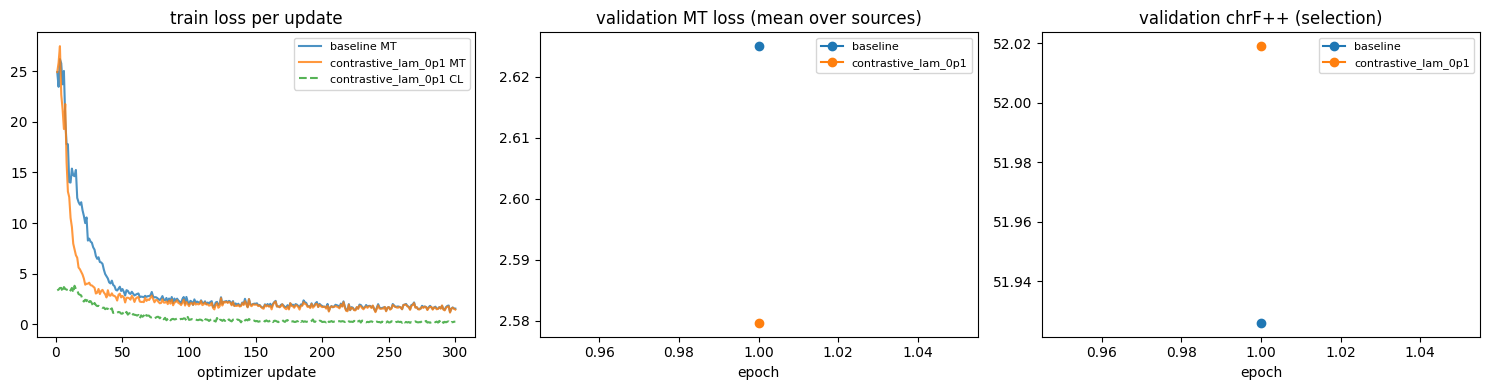

In [12]:
plot_learning_curves(histories, out / "figures" / "learning_curves.png");

How large is λ·L_CL compared with L_MT? If it is tiny, the contrastive term barely affects training.

In [13]:
h = histories[best_cl]
pd.DataFrame([{"epoch": e["epoch"], "train_mt": e["train_mt"], "train_cl": e["train_cl"],
               "lambda*cl": h["lambda_cl"] * e["train_cl"]} for e in h["epochs"]]).round(4)

,epoch,train_mt,train_cl,lambda*cl
0,1,2.8175,0.7226,0.0723


## 6. Test evaluation: chrF++ and encoder retrieval

In [14]:
result = evaluate_test(cfg, splits, {"baseline": "baseline", "contrastive": best_cl}, device)
display(results_table(result["metrics"], histories).round(3).T)
display(delta_table(result["metrics"]).round(3))

The tokenizer you are loading from '/content/drive/MyDrive/naijattention/outputs/pilot/baseline/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


evaluated baseline (baseline)


The tokenizer you are loading from '/content/drive/MyDrive/naijattention/outputs/pilot/contrastive_lam_0p1/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


evaluated contrastive (contrastive_lam_0p1)


model,baseline,contrastive
run,baseline,contrastive_lam_0p1
chrF++ mafand,59.301,59.486
chrF++ naija,52.17,52.427
chrF++ pooled,58.109,58.305
R@1 mafand,0.695,0.902
R@1 pcm->en mafand,0.526,0.933
R@1 naija,0.584,0.816
R@1 pcm->en naija,0.568,0.809
R@1 pooled,0.638,0.863
R@1 pcm->en pooled,0.531,0.877


,baseline,contrastive,delta,ci95_lo,ci95_hi,ci_excludes_0
metric,,,,,,
chrF++ mafand,59.301,59.486,0.185,0.048,0.331,True
chrF++ naija,52.170,52.427,0.257,-0.281,0.738,False
chrF++ pooled,58.109,58.305,0.196,0.054,0.359,True
R@1 en->pcm mafand (chance 0.0006),0.695,0.902,0.207,0.189,0.228,True
R@1 en->pcm naija (chance 0.0010),0.584,0.816,0.231,0.204,0.258,True
R@1 en->pcm pooled (chance 0.0004),0.638,0.863,0.226,0.209,0.243,True


chrF++ is SacreBLEU corpus chrF with `word_order=2`, computed separately per test source. The 95% CIs come
from a paired bootstrap over test rows: they cover test-sample noise but **not** seed-to-seed training variance.
Retrieval ranks every English test sentence against all Pidgin references in the same pool. Strict R@1 is
`argmax == gold`; the relaxed variant accepts identical-text duplicates, which matters for Naija's repeated short utterances.

,mafand,naija,pooled
baseline:n,1564.0000,972.0000,2536.0000
baseline:chance_r1,0.0006,0.0010,0.0004
baseline:en2pcm_r@1,0.6950,0.5844,0.6376
baseline:en2pcm_r@5,0.8069,0.7541,0.7701
baseline:en2pcm_r@10,0.8459,0.8014,0.8170
baseline:pcm2en_r@1,0.5256,0.5679,0.5312
baseline:en2pcm_r@1_relaxed,0.6950,0.5988,0.6431
baseline:mean_pos_cos,0.8205,0.7530,0.7946
baseline:median_pos_cos,0.8332,0.7670,0.8089
baseline:mean_hardest_neg_cos,0.7959,0.7418,0.7777


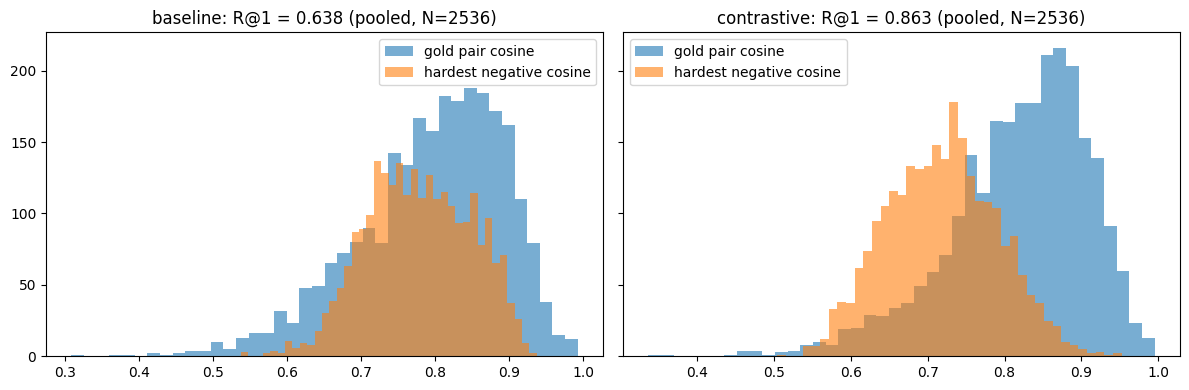

In [15]:
display(pd.DataFrame({pool: {f"{role}:{k}": v for role in ("baseline", "contrastive")
                             for k, v in result["metrics"]["retrieval"][pool][role].items()}
                      for pool in result["metrics"]["retrieval"]}).round(4))
plot_alignment(result["retrieval_raw"], out / "figures" / "alignment_histogram.png");

## 7. Paired examples

In [16]:
tr = result["translations"].assign(diff=lambda d: d["chrf_contrastive"] - d["chrf_baseline"])
cols = ["source", "english", "reference", "hyp_baseline", "hyp_contrastive", "diff"]
print("contrastive better:"); display(tr.nlargest(3, "diff")[cols])
print("baseline better:");    display(tr.nsmallest(3, "diff")[cols])
both_bad = tr[(tr["chrf_baseline"] < 20) & (tr["chrf_contrastive"] < 20)]
print("both poor:");           display(both_bad.head(3)[cols])

contrastive better:


,source,english,reference,hyp_baseline,hyp_contrastive,diff
1987,naija,Haha,Haha.,Hehe,Haha,60.941613
2535,naija,Thank you!,Thank you!,"Wetin we call dis foto, thank you!",Thank you!,50.610395
64,mafand,Suarez Zone,Suarez Zone,Surez Zone,Suarez Zone,45.260864


baseline better:


,source,english,reference,hyp_baseline,hyp_contrastive,diff
654,mafand,"GOD DEY,","GOD DEY,","GOD DEY,","God dey, God dey dey,",-93.932185
1914,naija,Lit-...,Lit-...,"Wetin we call dis foto, Lit-...","Wetin we call dis foto,",-51.235605
655,mafand,NIGERIA GO BETTER!,NIGERIA GO BETTER!,NIGERIA GO BETTER!,NIGERIA go BETTER!,-38.104500


both poor:


,source,english,reference,hyp_baseline,hyp_contrastive,diff
6,mafand,One of the deceased colleagues said several efforts to locate her did not yield results until a commercial motorcycl...,"one of di office pipo of di pesin wey die tok say as dem try to find am reach, dem no see am until one okada man kom...",One of di deceased colleagues say several efforts to locate her no yield results until commercial motorcyclist discl...,One of di deceased colleagues say several efforts to locate her no yield results until a commercial motorcyclist dis...,0.837950
42,mafand,"We will use every peaceful and constitutional means available to attain this objective,he added.","We go use all di way wey no go kos fight, wey follow law, to do di thing. As e take tok am.","We go use every peaceful and constitutional mean available to attain dis objective, e add.","We go use every peaceful and constitutional means available to attain dis objective, e add.",-0.029662
65,mafand,Just over a week ago,E just pass one week small,Just over week ago,Just over a week ago,0.419448


## 8. Human evaluation (blinded)

`results/human_eval_template.csv` contains predeclared *simple* and *difficult* test items (chosen from the
English side only), with the two systems shuffled into A/B per row. Fluent Nigerian Pidgin speakers score
semantic preservation, grammar and naturalness (1 = severe failure, 3 = understandable with significant
issues, 5 = strong) before opening the key file. Scores are never generated here.

In [17]:
pd.read_csv(out / "results" / "human_eval_template.csv").head()

,item_id,source,difficulty,english,reference_pidgin,system_A,system_B,A_semantic_1to5,A_grammar_1to5,A_naturalness_1to5,B_semantic_1to5,B_grammar_1to5,B_naturalness_1to5,error_notes,reference_problem
0,h000,mafand,simple,What then is your position on open grazing?,Wetin beyour position about open grazing?,Wetin na your position for open grazing?,"Wetin we call dis foto, wetin na your position for open grazing?",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,h001,mafand,simple,Suarez Zone,Suarez Zone,Suarez Zone,Surez Zone,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,h002,mafand,simple,Impeaching the president has a process.,E get process wey dem dey take impeach president.,Impeaching di president don process.,Impeaching di president don a process.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,h003,mafand,simple,Serena sails past teenager Pigato in Parma WTA,Serena don cruise pass teenager Pigato for Parma Wta.,Serena sail past teenager Pigato for Parma WTA,Serena sail past teenager Pigato for Parma WTA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,h004,mafand,simple,This killing is very distasteful to me.,Di kilin bitter for my mouth welwel.,Dis killing na very distasteful to me.,Dis killing dey very distasteful to me.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
# After scoring: set the path to the completed sheet and run this cell.
SCORED = out / "results" / "human_eval_scored.csv"
if SCORED.exists():
    s = pd.read_csv(SCORED); key = pd.read_csv(out / "results" / "human_eval_KEY_do_not_open_before_scoring.csv")
    s = s.merge(key, on="item_id", suffixes=("", "_sys"))
    long = []
    for slot in ("A", "B"):
        for crit in ("semantic_1to5", "grammar_1to5", "naturalness_1to5"):
            long.append(pd.DataFrame({"system": s[f"system_{slot}_sys"], "difficulty": s["difficulty"],
                                      "criterion": crit, "score": s[f"{slot}_{crit}"]}))
    display(pd.concat(long).groupby(["criterion", "difficulty", "system"])["score"].agg(["mean", "count"]).unstack())
else:
    print("no scored sheet yet:", SCORED)

no scored sheet yet: /content/drive/MyDrive/naijattention/outputs/pilot/results/human_eval_scored.csv


## 9. Inference demo: English (e.g. LLM output) → Pidgin

A demonstration only. Text outside the news and spoken training domains is **unverified generalisation**, and
sentence-by-sentence translation loses cross-sentence context.

In [19]:
example_llm_output = ("Drink plenty of water when the weather is hot. "
                      "If you feel dizzy, sit down in a cool place and rest. "
                      "The clinic opens at eight o'clock tomorrow morning.")
for role, run in {"baseline": "baseline", "contrastive": best_cl}.items():
    m, t = load_best(out / run, device)
    print(f"{role:>12}:", translate_to_pidgin(example_llm_output, m, t, cfg.source_prefix, device, precision,
                                              num_beams=cfg.num_beams, max_new_tokens=cfg.max_new_tokens))
    del m; free_memory()

The tokenizer you are loading from '/content/drive/MyDrive/naijattention/outputs/pilot/baseline/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


    baseline: Drink plenty of water wen di weather dey hot. If you feel dizzy, sit down for cool place and rest. Di clinic open for eight o'clock tomorrow morning.


The tokenizer you are loading from '/content/drive/MyDrive/naijattention/outputs/pilot/contrastive_lam_0p1/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


 contrastive: Drink plenty water wen di weather dey hot. If you feel dizzy, sit down for cool place and rest. Di clinic open at eight o'clock tomorrow morning.


## 10. Integrity checks and reproducibility

In [20]:
ic = integrity_checks(cfg, splits, histories, result)
save_json(ic, out / "results" / "integrity_checks.json")
print(json.dumps(ic, indent=1))
print("outputs in", out.resolve())
if not cfg.is_research_run:
    print(f"\n{cfg.run_label.upper()} RUN COMPLETE - numbers above are not research results.")

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
The tokenizer you are loading from '/content/drive/MyDrive/naijattention/outputs/pilot/baseline/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
The tokenizer you are loading from '/content/drive/MyDrive/naijattention/outputs/pilot/contrastive_lam_0p1/best' with a

{
 "same_test_rows_for_both_systems": true,
 "matched_optimizer_updates": true,
 "matched_effective_batch": true,
 "no_test_rows_in_train": true,
 "deterministic_generation": true,
 "checkpoints_exist": true,
 "all_metrics_finite": true,
 "saved_tokenizers_match_original": true
}
outputs in /content/drive/MyDrive/naijattention/outputs/pilot

PILOT RUN COMPLETE - numbers above are not research results.


## 11. Limitations (fill in after the full run)

- Single seed: the bootstrap CIs do not include training variance. Re-run with 2–3 seeds before claiming an effect.
- Mismatched train/eval: about two thirds of training is MTurk data, which appears in neither validation nor test.
- In-batch negatives: the contrastive signal depends on batch size; duplicate texts are masked but paraphrases are not.
- Reference quality: Naija English glosses of spoken utterances, and freer MTurk translations, penalise valid outputs.
- Retrieval is directly optimised by the contrastive model, so better R@1 alone is expected; the open question is whether chrF++ follows.
- Licences: MAFAND is CC BY-NC 4.0, Naija-NSC is CC BY-SA 4.0, and the MTurk licence is unconfirmed. Don't redistribute the merged corpus.

**Reproduce:** `python scripts/run_experiment.py` (or this notebook) with the saved `config.json`. Data files are
pinned by commit SHA and checked against expected row counts.